In [1]:
import geoutils as gu

import matplotlib.pyplot as plt
import numpy as np
from geoutils.stats import nmad

import xdem

In [2]:
## VARIOGRAMS

dh = xdem.DEM(r"PV_data/Zones/zone1_Bw/z1_diff_after.tif")
dh.load()

In [ ]:
## BW with 500 subsamples
'''
df = xdem.spatialstats.sample_empirical_variogram(
    values=dh, subsample=500, n_variograms=5, estimator="dowd", random_state=42
)
#xdem.spatialstats.plot_variogram(df)
#func_sum_vgm1, params_vgm1 = xdem.spatialstats.fit_sum_model_variogram(
#    list_models=["Spherical"], empirical_variogram=df
#)

func_sum_vgm2, params_vgm2 = xdem.spatialstats.fit_sum_model_variogram(
    list_models=["Spherical", "Spherical"], empirical_variogram=df
)

xdem.spatialstats.plot_variogram(
    df,
    list_fit_fun=[func_sum_vgm2],
    list_fit_fun_label=["Model Fit"],
    ylim = (0,0.5),
    xlim = (0,400)

)
'''

/home/mad/miniconda3/envs/xdem-dev/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


       model       range     psill
0  spherical   15.112500  0.120698
0  spherical  527.774838  0.080913


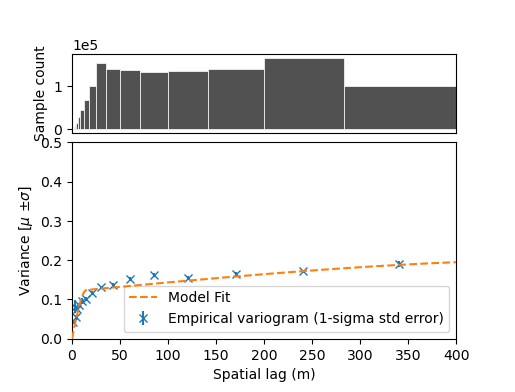

In [3]:
## BW with 1000 subsamples
df = xdem.spatialstats.sample_empirical_variogram(
    values=dh, subsample=1000, n_variograms=5, estimator="dowd", random_state=42
)


func_sum_vgm2, params_vgm2 = xdem.spatialstats.fit_sum_model_variogram(
    list_models=["Spherical", "Spherical"], empirical_variogram=df
)

xdem.spatialstats.plot_variogram(
    df,
    list_fit_fun=[func_sum_vgm2],
    list_fit_fun_label=["Model Fit"],
    ylim = (0,0.5),
    xlim = (0,400)

)

print(params_vgm2)

In [ ]:
# Correlated uncertainty from variogram
dh_array = dh.data

sigma_corr2 = params_vgm2["psill"].sum()
sigma_corr = np.sqrt(sigma_corr2)

# Uncorrelated uncertainty (RMSE or std of elevation differences)
sigma_uncorr_std = np.nanstd(dh)
valid_vals = dh[~np.isnan(dh_array)]      # remove NaNs
sigma_uncorr = np.sqrt(np.mean(valid_vals**2))

# Total mean uncertainty
sigma_total = np.sqrt(sigma_corr**2 + sigma_uncorr**2)

print("Variogram results for Nonlinear Blockwise (1,000 subsampes)")
print("Correlated uncertainty from variogram: ", sigma_corr)
print("Uncorrelated uncertainty (RMSE): ", sigma_uncorr)
print("std uncorr: ",sigma_uncorr_std)
print("Total mean uncertainty: ", sigma_total)

Variogram results for Nonlinear Blockwise (1,000 subsampes)
Correlated uncertainty from variogram:  0.4490114151099154
Uncorrelated uncertainty (RMSE):  0.6390569529173941
std uncorr:  0.6174415905960385
Total mean uncertainty:  0.7810281940948567


LINEAR NAATH VARIOGRAM

In [7]:

## NAATH 
naath_path = r"PV_data/Zones/zone1_naath/naath_b1_diff_after.tif"
dh_n = xdem.DEM(naath_path)
dh_n.load()

In [8]:
df_n = xdem.spatialstats.sample_empirical_variogram(
    values=dh_n, subsample=1000, n_variograms=5, estimator="dowd", random_state=42
)
#xdem.spatialstats.plot_variogram(df_n)

       model        range     psill
0  spherical    30.188655  0.191089
0  spherical  1595.852800  0.266595


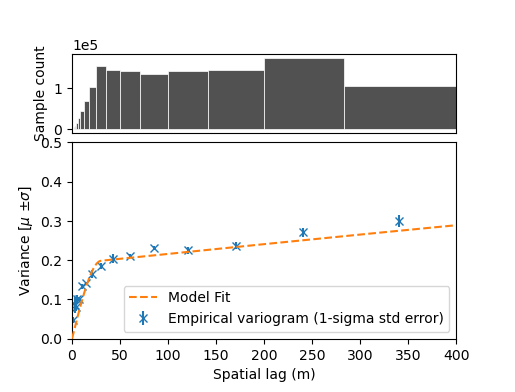

In [9]:
func_sum_vgm2, params_vgm2 = xdem.spatialstats.fit_sum_model_variogram(
    list_models=["Spherical", "Spherical"], empirical_variogram=df_n
)

xdem.spatialstats.plot_variogram(
    df_n,
    list_fit_fun=[func_sum_vgm2],
    list_fit_fun_label=["Model Fit"],
    ylim = (0,0.5),
    xlim = (0,400)
)

print(params_vgm2)

In [10]:
# Correlated uncertainty from variogram
dh_n_array = dh_n.data
sigma_corr2 = params_vgm2["psill"].sum()
sigma_corr = np.sqrt(sigma_corr2)

# Uncorrelated uncertainty (RMSE or std of elevation differences)
sigma_uncorr_std = np.nanstd(dh_n_array)
valid_vals = dh_n[~np.isnan(dh_n_array)]      # remove NaNs
sigma_uncorr = np.sqrt(np.mean(valid_vals**2))

# Total mean uncertainty
sigma_total = np.sqrt(sigma_corr**2 + sigma_uncorr**2)

print("Variogram results for Linear Nuth and Kaab (1,000 subsampes)")
print("Correlated uncertainty from variogram: ", sigma_corr)
print("Uncorrelated uncertainty (RMSE): ", sigma_uncorr)
print("Uncorrelated uncertainty (std): ", sigma_uncorr_std)
print("Total mean uncertainty: ", sigma_total)

Variogram results for Linear Nuth and Kaab (1,000 subsampes)
Correlated uncertainty from variogram:  0.6765234754382256
Uncorrelated uncertainty (RMSE):  0.698957574206622
Uncorrelated uncertainty (std):  0.69890666
Total mean uncertainty:  0.9727413342506942


ICP VARIOGRAM

In [12]:
## ICP VARIOGRAM
og_path = r"PV_datadifferencing/dtm_diff.tif"
dh_i = xdem.DEM(og_path)
dh_i.load()

df_i = xdem.spatialstats.sample_empirical_variogram(
    values=dh_i, subsample=1000, n_variograms=5, estimator="dowd", random_state=42
)
#xdem.spatialstats.plot_variogram(df_n)


/home/mad/miniconda3/envs/xdem-dev/lib/python3.13/site-packages/geoutils/raster/raster.py:1748: UserWarning: Setting default nodata -99999 to mask non-finite values found in the array, as no nodata value was defined.
  warnings.warn(
/home/mad/miniconda3/envs/xdem-dev/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/mad/miniconda3/envs/xdem-dev/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/mad/miniconda3/envs/xdem-dev/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/mad/miniconda3/envs/xdem-dev/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepd

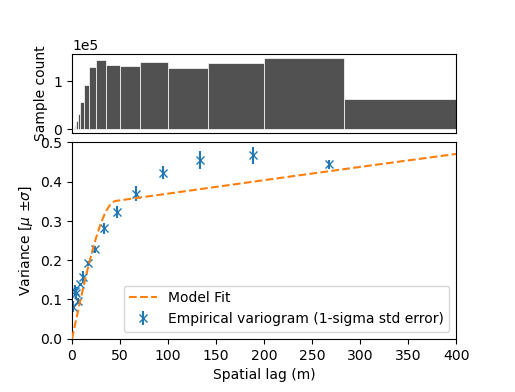

In [13]:
func_sum_vgm2, params_vgm2 = xdem.spatialstats.fit_sum_model_variogram(
    list_models=["Spherical", "Spherical"], empirical_variogram=df_i
)

xdem.spatialstats.plot_variogram(
    df_i,
    list_fit_fun=[func_sum_vgm2],
    list_fit_fun_label=["Model Fit"],
    xlim = (0,400),
    ylim = (0,0.5)
    
)


In [16]:
print(params_vgm2)

       model        range     psill
0  spherical    45.600557  0.335348
0  spherical  1768.969001  0.406374


In [15]:
# Correlated uncertainty from variogram
dh_i_array = dh_i.data
sigma_corr2 = params_vgm2["psill"].sum()
sigma_corr = np.sqrt(sigma_corr2)

# Uncorrelated uncertainty (RMSE or std of elevation differences)
sigma_uncorr_std = np.nanstd(dh_i_array)
valid_vals = dh_i[~np.isnan(dh_i_array)]      # remove NaNs
sigma_uncorr = np.sqrt(np.mean(valid_vals**2))

# Total mean uncertainty
sigma_total = np.sqrt(sigma_corr**2 + sigma_uncorr**2)

print("Variogram results for Linear Nuth and Kaab (1,000 subsampes)")
print("Correlated uncertainty from variogram: ", sigma_corr)
print("Uncorrelated uncertainty (RMSE): ", sigma_uncorr)
print("Uncorrelated uncertainty (std): ", sigma_uncorr_std)
print("Total mean uncertainty: ", sigma_total)

Variogram results for Linear Nuth and Kaab (1,000 subsampes)
Correlated uncertainty from variogram:  0.8612323691337408
Uncorrelated uncertainty (RMSE):  0.9517079817263068
Uncorrelated uncertainty (std):  0.9479774
Total mean uncertainty:  1.2835377969211799
